# Matrices con Python: operar, despejar y multiplicar
**BCD3103 · Álgebra Lineal y Ecuaciones Diferenciales · Lead University**

En este cuaderno repasamos con **NumPy** lo mismo que vimos en clase, con los mismos ejemplos de la guía:

1. Crear y leer una matriz
2. Transponer
3. Sumar, restar y escalar
4. Despejar una matriz $X$ en una ecuación
5. Producto matriz por vector
6. Producto de matrices
7. **Caso práctico de IA:** entrenar un clasificador (regresión logística) usando solo operaciones de matrices

> Ejecute las celdas en orden (**Shift + Enter**). Antes de ejecutar cada resultado, intente predecirlo a mano.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)   # imprime números más limpios

## 1. Crear y leer una matriz

Una matriz $A$ de tamaño $m \times n$ tiene $m$ filas y $n$ columnas. En NumPy se crea con una lista de filas. La propiedad `shape` devuelve `(m, n)`.

> ⚠️ **Índices:** en matemáticas $a_{ij}$ cuenta desde 1 (fila $i$, columna $j$), pero Python cuenta desde 0. Por eso $a_{23}$ se lee como `A[1, 2]`.

In [2]:
A = np.array([[2, -1,  3],
              [0,  4, -2]])

print("A =\n", A)
print("tamaño (m, n):", A.shape)        # (2, 3)
print("a_23 =", A[1, 2])                  # fila 2, columna 3  ->  -2
print("fila 1   :", A[0, :])              # primera fila como vector
print("columna 3:", A[:, 2])              # tercera columna como vector

A =
 [[ 2 -1  3]
 [ 0  4 -2]]
tamaño (m, n): (2, 3)
a_23 = -2
fila 1   : [ 2 -1  3]
columna 3: [ 3 -2]


## 2. Transpuesta

$(A^T)_{ij} = a_{ji}$: las filas se vuelven columnas. Si $A$ es $m\times n$, entonces $A^T$ es $n\times m$.
Una matriz es **simétrica** si $A = A^T$.

In [3]:
print("A.T =\n", A.T)
print("tamaño de A.T:", A.T.shape)                 # (3, 2)
print("(A.T).T == A ?", np.array_equal(A.T.T, A))  # True

D = np.array([[ 1, 2, -3],
              [ 2, 0,  5],
              [-3, 5,  4]])
print("¿D es simétrica?", np.array_equal(D, D.T))  # True

A.T =
 [[ 2  0]
 [-1  4]
 [ 3 -2]]
tamaño de A.T: (3, 2)
(A.T).T == A ? True
¿D es simétrica? True


## 3. Sumar, restar y escalar

- **Sumar o restar:** entrada por entrada. Solo si las matrices tienen **el mismo tamaño**.
- **Escalar:** el número multiplica **cada** entrada.

Calculemos $2A - 3B$ (Ejercicio 1 de la guía).

In [4]:
A = np.array([[2, -1,  3],
              [0,  4, -2]])
B = np.array([[1,  0, -2],
              [3, -1,  4]])

print("2A =\n", 2*A)
print("3B =\n", 3*B)
print("2A - 3B =\n", 2*A - 3*B)
print("\nEntrada (1,1): 2*2 - 3*1 =", 2*A[0,0] - 3*B[0,0])

2A =
 [[ 4 -2  6]
 [ 0  8 -4]]
3B =
 [[ 3  0 -6]
 [ 9 -3 12]]
2A - 3B =
 [[  1  -2  12]
 [ -9  11 -16]]

Entrada (1,1): 2*2 - 3*1 = 1


**Propiedad:** la transpuesta respeta la suma y el escalar: $(A+B)^T = A^T + B^T$ y $(kA)^T = kA^T$.

In [5]:
print("(A+B).T == A.T + B.T ?", np.array_equal((A+B).T, A.T + B.T))
print("(5A).T == 5*A.T     ?", np.array_equal((5*A).T, 5*A.T))

# Si los tamaños no coinciden, NumPy se queja (igual que en matemáticas):
try:
    A + np.array([[1, 2], [3, 4]])
except ValueError as e:
    print("\nError esperado:", e)

(A+B).T == A.T + B.T ? True
(5A).T == 5*A.T     ? True

Error esperado: operands could not be broadcast together with shapes (2,3) (2,2) 


## 4. Despejar una matriz $X$

Se despeja como con números (pasar sumando o restando, multiplicar por un escalar), pero **no** se divide entre una matriz.

Sean $A=\begin{bmatrix}3&1\\-2&4\end{bmatrix}$ y $B=\begin{bmatrix}7&5\\2&-6\end{bmatrix}$.

**(a)** $2X + A = B \;\Rightarrow\; 2X = B - A \;\Rightarrow\; X = \tfrac12 (B-A)$

**(b)** $3X - A = X + B \;\Rightarrow\; 2X = A + B \;\Rightarrow\; X = \tfrac12 (A+B)$

In [6]:
A = np.array([[ 3, 1],
              [-2, 4]])
B = np.array([[ 7, 5],
              [ 2,-6]])

# (a) 2X + A = B
Xa = 0.5 * (B - A)
print("Xa =\n", Xa)
print("¿2Xa + A == B ?", np.allclose(2*Xa + A, B))

# (b) 3X - A = X + B
Xb = 0.5 * (A + B)
print("\nXb =\n", Xb)
print("¿3Xb - A == Xb + B ?", np.allclose(3*Xb - A, Xb + B))

Xa =
 [[ 2.  2.]
 [ 2. -5.]]
¿2Xa + A == B ? True

Xb =
 [[ 5.  3.]
 [ 0. -1.]]
¿3Xb - A == Xb + B ? True


> 💡 **Siempre verifique** sustituyendo en la ecuación original. `np.allclose` compara matrices tolerando pequeños errores de redondeo.

## 5. Producto matriz por vector

Si $A$ es $m\times n$ y $x$ tiene $n$ componentes, $Ax$ tiene $m$ componentes: cada entrada es una **fila de $A$ punto $x$**.

Ejemplo: una capa de red neuronal con 2 neuronas y 3 entradas. Cada fila de $A$ son los pesos de una neurona.

In [7]:
A = np.array([[2, -1, 3],
              [4,  0, 5]])     # 2 x 3  (pesos)
x = np.array([1, 2, -1])        # 3 entradas

y = A @ x                       # el operador @ es el producto matricial
print("A @ x =", y)             # [-3 -1]

# Paso a paso: cada entrada es (fila de A) . x
print("fila 1 . x =", np.dot(A[0], x))   # 2*1 + (-1)*2 + 3*(-1) = -3
print("fila 2 . x =", np.dot(A[1], x))   # 4*1 +  0*2 + 5*(-1) = -1

A @ x = [-3 -1]
fila 1 . x = -3
fila 2 . x = -1


**Otra mirada:** $Ax$ es una **combinación lineal de las columnas** de $A$, con los números de $x$ como coeficientes.

In [8]:
combinacion = x[0]*A[:, 0] + x[1]*A[:, 1] + x[2]*A[:, 2]
print("1*(2,4) + 2*(-1,0) + (-1)*(3,5) =", combinacion)
print("¿coincide con A @ x ?", np.array_equal(combinacion, A @ x))

1*(2,4) + 2*(-1,0) + (-1)*(3,5) = [-3 -1]
¿coincide con A @ x ? True


## 6. Producto de matrices

$(m\times n)\cdot(n\times p) = (m\times p)$: los números de **adentro** deben coincidir y los de **afuera** dan el tamaño. La entrada $(i,j)$ es la fila $i$ de $A$ punto la columna $j$ de $B$.

In [9]:
A = np.array([[ 1, 2, 0],
              [-1, 3, 4]])      # 2 x 3
B = np.array([[ 2, 1],
              [ 0,-3],
              [ 5, 2]])         # 3 x 2

AB = A @ B
print("AB =\n", AB)             # [[ 2 -5], [18 -2]]
print("tamaño:", A.shape, "@", B.shape, "->", AB.shape)

# Entrada (2,1) a mano: fila 2 de A punto columna 1 de B
print("c_21 =", np.dot(A[1, :], B[:, 0]))   # (-1)*2 + 3*0 + 4*5 = 18

AB =
 [[ 2 -5]
 [18 -2]]
tamaño: (2, 3) @ (3, 2) -> (2, 2)
c_21 = 18


### El producto **no** conmuta: $AB \neq BA$

In [10]:
BA = B @ A
print("BA tiene tamaño", BA.shape, "y AB tiene tamaño", AB.shape)   # (3,3) vs (2,2)

P = np.array([[1, 2], [3, 4]])
Q = np.array([[0, 1], [1, 0]])
print("\nPQ =\n", P @ Q, "   <- intercambia las COLUMNAS de P")
print("QP =\n", Q @ P, "   <- intercambia las FILAS de P")

BA tiene tamaño (3, 3) y AB tiene tamaño (2, 2)

PQ =
 [[2 1]
 [4 3]]    <- intercambia las COLUMNAS de P
QP =
 [[3 4]
 [1 2]]    <- intercambia las FILAS de P


> ⚠️ **Error común:** `A * B` multiplica **entrada por entrada** (producto de Hadamard), *no* es el producto de matrices. Para el producto de matrices use `@`.

In [11]:
M = np.array([[1, 2], [3, 4]])
N = np.array([[0, 1], [1, 0]])
print("M * N  (entrada por entrada) =\n", M * N)
print("M @ N  (producto matricial)  =\n", M @ N)

M * N  (entrada por entrada) =
 [[0 2]
 [3 0]]
M @ N  (producto matricial)  =
 [[2 1]
 [4 3]]


---
## 7. Caso práctico de IA: predecir la fuga de clientes

Una empresa quiere predecir si un cliente **abandonará** el servicio (`1`) o se **quedará** (`0`) a partir de 3 variables:

| Variable | Significado |
|---|---|
| `meses` | antigüedad del cliente |
| `compras` | compras en el último trimestre |
| `quejas` | quejas registradas |

Un modelo de **regresión logística** es la neurona más simple de una red neuronal. Todo su entrenamiento se escribe con las operaciones de matrices que acabamos de ver:

| Paso | Fórmula | Operación de matrices |
|---|---|---|
| Datos | $X$ de tamaño $n\times 3$ | cada **fila** es un cliente y cada **columna** una variable |
| Predicción | $z = Xw + b$ | **matriz por vector** |
| Probabilidad | $p=\sigma(z)$ | función aplicada entrada por entrada |
| Gradiente | $g = \tfrac1n X^T (p-y)$ | **transpuesta**, producto, resta y escalar |
| Actualización | $w \leftarrow w - \eta\, g$ | **resta de vectores y escalar** |

### 7.1 Los datos como matriz
Generamos datos sintéticos (con semilla fija para que los resultados sean reproducibles).

In [12]:
rng = np.random.default_rng(42)
n = 300

# Matriz de datos X: n clientes (filas) x 3 variables (columnas)
meses   = rng.normal(24, 10, n)
compras = rng.normal(8, 3, n)
quejas  = rng.poisson(1.5, n)
X_raw = np.column_stack([meses, compras, quejas])

# "Verdad" oculta usada solo para fabricar las etiquetas y
w_real = np.array([-1.2, -0.9, 1.5]); b_real = -0.2
Xs_tmp = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
prob_real = 1 / (1 + np.exp(-(Xs_tmp @ w_real + b_real)))
y = (rng.random(n) < prob_real).astype(float)

print("X_raw tiene tamaño", X_raw.shape, "-> (clientes, variables)")
print("Primeras 3 filas (3 clientes):\n", X_raw[:3])
print("Fugas en los datos:", int(y.sum()), "de", n)

X_raw tiene tamaño (300, 3) -> (clientes, variables)
Primeras 3 filas (3 clientes):
 [[27.047 13.182  2.   ]
 [13.6    3.398  4.   ]
 [31.505 10.591  1.   ]]
Fugas en los datos: 136 de 300


### 7.2 Estandarizar (operaciones por columna)
Restamos a cada columna su media y dividimos entre su desviación estándar para que todas las variables tengan una escala comparable.

In [13]:
mu = X_raw.mean(axis=0)
sd = X_raw.std(axis=0)
X = (X_raw - mu) / sd          # resta y división columna por columna

print("medias de X ≈", X.mean(axis=0))
print("desv.  de X ≈", X.std(axis=0))

medias de X ≈ [ 0.  0. -0.]
desv.  de X ≈ [1. 1. 1.]


### 7.3 Una predicción con $Xw + b$ (matriz por vector)
Con pesos iniciales en cero el modelo aún no sabe nada: predice $p=0{,}5$ para todos.

In [14]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(3)                  # un peso por variable
b = 0.0

z = X @ w + b                    # (300 x 3) @ (3,) -> (300,)
p = sigmoid(z)
print("tamaños: X", X.shape, "| w", w.shape, "| z", z.shape)
print("primeras probabilidades:", p[:5])

tamaños: X (300, 3) | w (3,) | z (300,)
primeras probabilidades: [0.5 0.5 0.5 0.5 0.5]


### 7.4 El gradiente con la transpuesta
La pérdida (entropía cruzada) mide qué tan mal predice el modelo. Su gradiente respecto a $w$ es

$$g = \frac{1}{n} X^T (p - y)$$

Observe los tamaños: $X^T$ es $3\times n$ y $(p-y)$ es $n\times 1$, así que $g$ tiene 3 componentes, uno por peso.

In [15]:
def loss(p, y):
    eps = 1e-12
    return -np.mean(y*np.log(p+eps) + (1-y)*np.log(1-p+eps))

error = p - y                    # vector de n errores
g = (X.T @ error) / n            # (3 x n) @ (n,) -> (3,)
gb = error.mean()

print("pérdida inicial:", round(loss(p, y), 4))
print("gradiente g =", g, "  tamaño", g.shape)

pérdida inicial: 0.6931
gradiente g = [ 0.211  0.1   -0.232]   tamaño (3,)


In [16]:
import plotly.graph_objects as go
import pandas as pd

# Volvemos a inicializar el entrenamiento para registrar los pesos paso a paso
eta = 0.5
w_anim = np.zeros(3)
b_anim = 0.0

historial_w0 = []
historial_w2 = []
historial_loss = []
epocas_reg = []

# Registramos un subconjunto de épocas para que la animación sea fluida y rápida
for epoca in range(101):
    p = sigmoid(X @ w_anim + b_anim)
    error = p - y
    g = (X.T @ error) / n
    gb = error.mean()

    # Guardar estado actual antes de actualizar
    if epoca % 2 == 0:  # Guardamos cada 2 épocas
        historial_w0.append(w_anim[0])
        historial_w2.append(w_anim[2])
        historial_loss.append(loss(p, y))
        epocas_reg.append(epoca)

    w_anim = w_anim - eta * g
    b_anim = b_anim - eta * gb

# Crear DataFrame para Plotly
df_anim = pd.DataFrame({
    'Epoca': epocas_reg,
    'w_meses': historial_w0,
    'w_quejas': historial_w2,
    'Loss': historial_loss
})

# Crear figura de Plotly
fig = go.Figure(
    data=[go.Scatter(
        x=df_anim['w_meses'][:1],
        y=df_anim['w_quejas'][:1],
        mode='lines+markers+text',
        marker=dict(color='red', size=12, symbol='circle'),
        line=dict(color='orange', width=2),
        text=["Inicio (Época 0)"],
        textposition="top center",
        name='Trayectoria'
    )],
    layout=go.Layout(
        title='Animación del Descenso del Gradiente: Pesos (meses vs quejas)',
        xaxis=dict(range=[-1.8, 0.2], title='Peso de "meses" (w_0)'),
        yaxis=dict(range=[-0.2, 1.8], title='Peso de "quejas" (w_2)'),
        hovermode='closest',
        updatemenus=[dict(
            type='buttons',
            showactive=False,
            buttons=[dict(
                label='Reproducir',
                method='animate',
                args=[None, dict(frame=dict(duration=100, redraw=True), fromcurrent=True)]
            )]
        )]
    ),
    frames=[go.Frame(
        data=[go.Scatter(
            x=df_anim['w_meses'][:i+1],
            y=df_anim['w_quejas'][:i+1],
            mode='lines+markers',
            marker=dict(color='red', size=8),
            name='Trayectoria'
        )],
        layout=go.Layout(title=f"Época: {df_anim['Epoca'].iloc[i]} | Pérdida: {df_anim['Loss'].iloc[i]:.4f}")
    ) for i in range(len(df_anim))]
)

fig.show()

### 7.5 Entrenar: repetir la actualización $w \leftarrow w - \eta\, g$
Es **exactamente** la actualización "$W - \eta\,\bar G$" del Quiz #1: una resta de matrices y un escalar (la tasa de aprendizaje $\eta$).

In [17]:
eta = 0.5                         # tasa de aprendizaje
w = np.zeros(3); b = 0.0
historial = []

for epoca in range(200):
    p = sigmoid(X @ w + b)
    error = p - y
    g  = (X.T @ error) / n
    gb = error.mean()
    w = w - eta * g               # <-- resta de vectores y escalar
    b = b - eta * gb
    historial.append(loss(p, y))

print("pesos aprendidos w =", w, "  b =", round(b, 3))
print("pérdida final:", round(historial[-1], 4))

pesos aprendidos w = [-1.563 -0.679  1.671]   b = -0.233
pérdida final: 0.4118


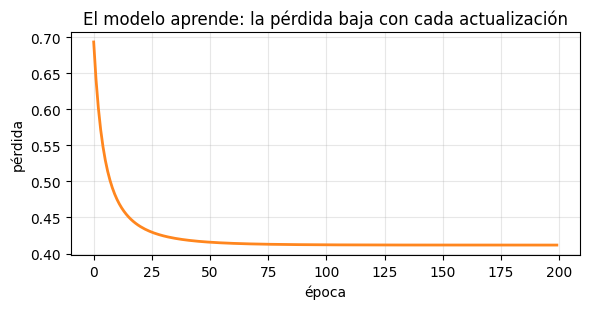

In [18]:
plt.figure(figsize=(6, 3.2))
plt.plot(historial, color="#FF861E", lw=2)
plt.xlabel("época"); plt.ylabel("pérdida")
plt.title("El modelo aprende: la pérdida baja con cada actualización")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

assert historial[-1] < historial[0]        # comprobación: sí aprendió

### 7.6 Evaluar con una matriz de confusión
Clasificamos como fuga si $p \ge 0{,}5$ y contamos aciertos y errores en una matriz $2\times2$ (filas = clase real, columnas = clase predicha), como en el Problema 12 del examen.

In [19]:
p = sigmoid(X @ w + b)
pred = (p >= 0.5).astype(int)
yi = y.astype(int)

# Matriz de confusión: filas = real (0,1), columnas = predicho (0,1)
M = np.zeros((2, 2), dtype=int)
for real, est in zip(yi, pred):
    M[real, est] += 1

print("Matriz de confusión (filas=real, columnas=predicho):\n", M)
print("Exactitud:", round(np.trace(M) / M.sum(), 3))   # suma de la diagonal / total

Matriz de confusión (filas=real, columnas=predicho):
 [[138  26]
 [ 34 102]]
Exactitud: 0.8


### 7.7 Interpretación
Los pesos aprendidos dicen cuánto pesa cada variable (en unidades estandarizadas). Un peso **negativo** reduce la probabilidad de fuga; uno **positivo** la aumenta.

In [20]:
for nombre, peso in zip(["meses", "compras", "quejas"], w):
    sentido = "aumenta" if peso > 0 else "reduce"
    print(f"{nombre:8s} peso = {peso:+.2f}  ->  {sentido} la probabilidad de fuga")

meses    peso = -1.56  ->  reduce la probabilidad de fuga
compras  peso = -0.68  ->  reduce la probabilidad de fuga
quejas   peso = +1.67  ->  aumenta la probabilidad de fuga


### 7.8 Predecir un cliente nuevo
Un cliente nuevo es una fila más. Se estandariza con la **misma** $\mu$ y $\sigma$ de entrenamiento y se aplica $xw+b$.

In [21]:
nuevo = np.array([50, 30, 10])               # 6 meses, 3 compras, 4 quejas
x_n = (nuevo - mu) / sd
prob = sigmoid(x_n @ w + b)
print(f"Probabilidad de fuga: {prob:.1%}")

Probabilidad de fuga: 81.3%


---
## 8. Ejercicios propuestos

1. Con $A$ y $B$ de la sección 3, calcule `A + 2*B` y verifique con papel y lápiz una entrada.
2. Despeje $X$ en $A - 2X = B$ (sección 4) y compruebe con `np.allclose`.
3. Calcule `np.array([[1,-2],[3,0],[2,5]]) @ np.array([4,1])` e interprete cada fila como una neurona.
4. En el caso de IA, cambie `eta` a `0.01` y a `5`. ¿Qué le pasa a la curva de pérdida? ¿Por qué?
5. Agregue una cuarta variable a `X` (por ejemplo, `soporte`). ¿Qué tamaño tienen ahora `X`, `w` y `g`?